# 各个包 to 配置

In [14]:
"""
MedicalGMU + X-ray + Clinical Tabular
- 影像(ResNet18)主导分类，临床特征仅做门控调制(GMU)
- 支持多任务辅助监督(aux_label)帮助影像学习形态特征
- 必须按病人(Group)划分训练/验证
"""

import os
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18

from sklearn.model_selection import KFold

current_dir = Path.cwd() #ipynb相当于cmd环境
root_dir = current_dir.parent 
text_path = root_dir / 'data' / 'raw' / 'tabular_data.xlsx'
pkl_path =  root_dir / 'data' / 'interim' 
image_root = root_dir / 'data'  / 'raw'/ 'image' 
resnet_weight = root_dir / 'weights' / 'resnet18.pth'
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
# device = torch.device("cuda:0")  
# weights = torch.tensor([1.0, 2.6132]).to(device)
# ========== 配置 ==========
CONFIG = {
	'excel_path': text_path,          # 包含 patient_id + feature_cols + aux_cols
	 'pkl_path': pkl_path / 'clinical.pkl', 
	'image_root': image_root,               # 病人影像根目录
	'save_dir':root_dir/ 'notebooks'/'result'/'MedCAT',
  'checkpoint_dir': root_dir/ 'notebooks'/'result'/'MedCAT',
	'img_size': 224,
	'batch_size': 8,                            # 医学影像显存占用大，建议8-16
	'epochs': 100,
	'lr_backbone': 1e-5,                       # 影像backbone小学习率微调
	'lr_head': 1e-3,                           # 临床塔/分类头大学习率
	'weight_decay': 1e-4,
	'dropout': 0.4,
	'patience': 15,
	'use_aux_task': True,                      # 是否用 aux_label 做多任务辅助
	'aux_weight': 0.3,                         # 辅助损失权重
	'pos_weight': 3,                         # III型(正类)加权
	'seed': 42,
	'device': torch.device("cuda:0") ,
	'resnet_weight':resnet_weight,
   'threshold': 0.25,  
   'num_folds': 5,
}

os.makedirs(CONFIG['save_dir'], exist_ok=True)
torch.manual_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])

# Multi-Modal DATASET

## 预处理

In [16]:
# ========== 1. 数据预处理（生成 clinical.pkl） ==========

def preprocess_and_save(excel_path, pkl_path):
	df = pd.read_excel(excel_path, header=1, nrows=280)
	df.columns = df.columns.str.strip()


	df_sorted = df.sort_values(by=['编号', '关节形态'], ascending=[True, False])
	patient_level =df.groupby('编号')['关节形态'].max().reset_index()
	# grouped = df.groupby('编号')
	# for patient_id, group_data in grouped:
	# 	print(f"=== 编号: {patient_id} 的分组 ===")
	# 	print(group_data)
	# 	print("----------------")
	# clinical_data = df.drop_duplicates(subset=['编号'], keep='first').copy()
	clinical_data = df_sorted.drop_duplicates(subset=['编号'], keep='first').copy()
	clinical_data = clinical_data.drop(columns= ['关节形态'])
	df = pd.merge(clinical_data, patient_level, on='编号')
	df['关节形态'] = df['关节形态'].apply(lambda x: 1 if x == 3 else 0)
	print(df.head())

	print(len(df))
	print(df.columns)
	data = pd.DataFrame()
	data['patient_id'] = df['编号'].astype(str).str.strip()
	# Categorical features (for Embedding)
	data['has_syrinx'] = df['合并脊髓空洞'].map({'是': 1, '有': 1, '否': 0, '无': 0}).fillna(0).astype(int)
	scale2_map = {'无痛': 0, '轻度疼痛': 1, '中度疼痛': 2, '重度疼痛': 3}
	data['scale2_1'] = df['疼痛分级'].map(scale2_map).fillna(0).astype(int)
	data['scale2_2'] = df['疼痛分级.1'].map(scale2_map).fillna(0).astype(int)
	data['scale2_3'] = df['疼痛分级.2'].map(scale2_map).fillna(0).astype(int)
	data['age']= df['年龄'].fillna(0).astype(int)
	data['gender']=df['性别'].map({'男': 1, '女': 0}).fillna(0).astype(int)
	asa_map = {'I': 0, 'II': 1, 'III': 2, 'IV': 3}
	data['asa']=df['ASA分级'].map(asa_map).fillna(0).astype(int)
	# Continuous features (for StandardScaler)
	data['syrinx_num'] = pd.to_numeric(df['脊髓空洞节段数量'], errors='coerce').fillna(0)
	data['syrinx_wide'] = pd.to_numeric(df['脊髓空洞最大宽度（只计算有空洞的）'], errors='coerce').fillna(0)
	data['CTH'] = pd.to_numeric(df['小脑扁桃体疝出程度'], errors='coerce').fillna(0)
	
	cisterna = pd.to_numeric(df['枕大池容积'], errors='coerce')
	# cisterna_max = cisterna.max()
	data['cisterna_flipped'] = (-cisterna).fillna(0)
	
	data['scale1'] = pd.to_numeric(df['量表1总分'], errors='coerce').fillna(0)
	data['scale3'] = pd.to_numeric(df['术前量表3总分'], errors='coerce').fillna(100)  # ADL，缺失=满分
	joa = pd.to_numeric(df['术前量表4总分'], errors='coerce')
	data['joa_flipped'] = (17 - joa).fillna(0)

	# 保存（标签从影像文件夹解析，这里不存label）
	data.to_pickle(pkl_path)
	print(f"[Preprocess] Saved clinical features to {pkl_path}")
	return data


In [17]:
data = preprocess_and_save(CONFIG['excel_path'], CONFIG['pkl_path'])
print(data)

   编号  年龄 性别                                       主诉      主诊断  \
0   1  29  男  枕颈部酸胀痛、四肢疼痛伴双眼复视1年,加重伴四肢乏力、行走不稳、尿频尿急2月。  II型颅底凹陷   
1   2  49  男                         双上肢乏力、麻木2年，伴便秘2周  II型颅底凹陷   
2   3  18  女                    颈部疼痛伴头痛7月余，加重伴行走不稳1月。  II型颅底凹陷   
3   4  67  女         头痛、右侧前臂及腰背部痛9月,件右手麻木、下肢乏力、行走缓慢3月  II型颅底凹陷   
4   5  32  女   颈枕部及右侧肢体胀痛，右侧肢体麻木乏力4月,上行性加重伴便秘、尿频尿急3月。  II型颅底凹陷   

                                                伴随诊断 既往疾病 既往手术史 既往过敏史  \
0  侧裂区蛛网膜囊肿(左侧)、颈椎间盘突出(C4/5和C6/7中央型突出,C5/6膨隆)、颈椎退行性变    无     无     无   
1             髓空洞症(C2-C6)、寰枕融合畸形、颈椎半脱位(C1/2左侧侧方关节)\n    无     无     无   
2                      :寰枢椎脱位、脊髓受压((延髓和上颈髓受压))上颌窦炎\n    无     无     无   
3                                       脊髓空洞症、寰枕融合畸形    无     无     无   
4                              脊髓空洞症、寰枢椎脱位、颈椎退行性病变\n    无     无     无   

                                              关节形态.1  ... 术前量表3总分比值    量表3分级  \
0  枕骨髁变成明显扁平且整体瘦小的骨骼形态；寰椎侧块严重畸形，上关节面的深度和曲率明显下降，前后...  ...       8.0   轻度功能障碍   
1  枕

# s数据集

In [4]:
class ChiariXrayDataset(Dataset):
	def __init__(self, pkl_path, image_root, patient_ids, transform=None,
				 scaler=None, fit_scaler=False):
		"""
		patient_ids: 当前Fold的病人ID列表（str）
		"""
		self.root_dir = Path(image_root)
		self.transform = transform
		self.samples = []

		# 加载临床表格
		df = pd.read_pickle(pkl_path)
		print(len(df))
		df['patient_id'] = df['patient_id'].astype(str).str.strip()
		df_indexed = df.set_index('patient_id')
		# print(df_indexed)
		# 特征列定义（与你上传的代码严格一致）
		self.cat_cols = ['has_syrinx', 'scale2_1', 'scale2_2', 'scale2_3','gender','asa']
		self.cont_cols = ['syrinx_num', 'syrinx_wide', 'CTH',
							'cisterna_flipped', 'scale1', 'scale3', 'joa_flipped','age']

		# Continuous 标准化（仅训练集fit）
		if fit_scaler:
			self.scaler = StandardScaler()
			df[self.cont_cols] = self.scaler.fit_transform(df[self.cont_cols])
		else:
			self.scaler = scaler
			if scaler is not None:
				df[self.cont_cols] = scaler.transform(df[self.cont_cols])

		# 遍历指定病人，解析影像文件夹
		for p_id in patient_ids:
			p_id_str = str(p_id).strip()
			if p_id_str not in df_indexed.index:
				continue

			row = df_indexed.loc[p_id_str]

			# Categorical: dict of int scalars
			cat_dict = {c: int(row[c]) for c in self.cat_cols}
			# Continuous: numpy array -> tensor
			cont_arr = row[self.cont_cols].values.astype(float)

			patient_folder = self.root_dir / p_id_str
			if not patient_folder.is_dir():
				continue

			# 遍历左右关节
			for side_folder in patient_folder.iterdir():
				if not side_folder.is_dir():
					continue
				folder_name = side_folder.name

				side = 'left' if '左' in folder_name else 'right'

				# 标签从文件夹名解析（3型/III型 = 1）
				if '3型' in folder_name or 'III型' in folder_name:
					label = 1
				else:
					label = 0

				# 遍历该关节下所有影像
				for img_file in side_folder.glob('*.*'):
					if img_file.suffix.lower() in ['.png', '.jpg', '.jpeg', '.tif', '.tiff']:
						self.samples.append({
							'path': str(img_file),
							'label': label,
							'patient_id': p_id_str,
							'side': side,
							'cat_dict': cat_dict,      # dict of ints
							'cont_arr': cont_arr.copy()  # float array
						})

		print(f"[Dataset] 病人: {len(set(s['patient_id'] for s in self.samples))}, "
				f"影像: {len(self.samples)}, "
				f"正类(III型): {sum(s['label'] for s in self.samples)}")

	def __len__(self):
		return len(self.samples)

	def __getitem__(self, idx):
		s = self.samples[idx]
		img = Image.open(s['path']).convert('L')
		if self.transform:
			img = self.transform(img)

		label = torch.tensor(s['label'], dtype=torch.long)

		# Categorical: dict of tensors (for Embedding)
		cat_features = {
			k: torch.tensor(v, dtype=torch.long)
			for k, v in s['cat_dict'].items()
		}
		# Continuous: tensor (already scaled)
		cont_features = torch.tensor(s['cont_arr'], dtype=torch.float32)

		joint_id = f"{s['patient_id']}_{s['side']}"

		return img, label, cat_features, cont_features, s['patient_id'], joint_id


def collate_fn(batch):
	"""拼接 batch，处理 dict 型 categorical features"""
	imgs = torch.stack([b[0] for b in batch])
	labels = torch.stack([b[1] for b in batch])

	cat_keys = batch[0][2].keys()
	cat_batch = {k: torch.stack([b[2][k] for b in batch]) for k in cat_keys}

	cont_batch = torch.stack([b[3] for b in batch])
	patient_ids = [b[4] for b in batch]
	joint_ids = [b[5] for b in batch]

	return imgs, labels, cat_batch, cont_batch, patient_ids, joint_ids

# 模型

In [5]:
import torch
import torch.nn as nn
from torchvision.models import resnet18


class ClinicalEncoder(nn.Module):
	"""
	临床表格编码器：
	- Categorical -> Embedding
	- Continuous -> StandardScaler后投影
	- 融合 -> 16-d 临床表示
	"""
	def __init__(self, cont_dim=7, out_dim=16):
		super().__init__()

		self.embeddings = nn.ModuleDict({
			'has_syrinx': nn.Embedding(2, 2),      # 2 classes
			'scale2_1': nn.Embedding(4, 3),         # 4 classes (0-3)
			'scale2_2': nn.Embedding(4, 3),
			'scale2_3': nn.Embedding(4, 3),
			'gender': nn.Embedding(2,2),
			'asa': nn.Embedding(4,3),		
		})
		cat_dim = 2 + 3 + 3 + 3  +3+2# 16

		self.cont_proj = nn.Sequential(
			nn.Linear(cont_dim, 16),
			nn.BatchNorm1d(16),
			nn.ReLU(),
			nn.Dropout(0.2)
		)

		self.fusion = nn.Sequential(
			nn.Linear(cat_dim + 16, out_dim),
			nn.LayerNorm(16),
			nn.Dropout(p=0.1)
		)

	def forward(self, cat_features, cont_features):
		embeds = []
		for key, emb in self.embeddings.items():
			embeds.append(emb(cat_features[key]))
		cat_feat = torch.cat(embeds, dim=-1)  # [B, 11]

		cont_feat = self.cont_proj(cont_features)  # [B, 16]
		combined = torch.cat([cat_feat, cont_feat], dim=-1)  # [B, 27]
		return self.fusion(combined)  # [B, 16]


class MedicalConcatNet(nn.Module):
	def __init__(self, num_cont=7, clin_out=16, pretrained_path=None):
		super().__init__()

		# --- 影像塔：ResNet18，单通道 X-ray ---
		self.resnet = resnet18(weights='DEFAULT')
		num_ftrs = self.resnet.fc.in_features

		self.resnet.fc = nn.Identity()
		if pretrained_path:
			self.load_smart_weights(pretrained_path)

		# --- 临床塔 ---
		self.clinical_encoder = ClinicalEncoder(cont_dim=num_cont, out_dim=clin_out)

		# --- 分类头：直接拼接影像 + 临床特征 ---
		self.classifier = nn.Sequential(
			nn.Linear(512 + clin_out, 2),
			# nn.BatchNorm1d(256),
			# nn.ReLU(),
			# nn.Dropout(0.2),
			# nn.Linear(256, 2)
		)

		self._init_weights()

	def load_smart_weights(self, path):
		print(f"正在加载权重文件: {path}")
		state_dict = torch.load(path, map_location='cpu')
		possible_keys = ['state_dict', 'model', 'net', 'model_state_dict']
		for key in possible_keys:
			if key in state_dict and isinstance(state_dict[key], dict):
				print(f"发现权重被包裹在 '{key}' 中，正在拆包...")
				state_dict = state_dict[key]
				break
		model_state_dict = self.state_dict()
		new_state_dict = {}
		matched_layers = 0
		print(f" 开始匹配 (文件包含 {len(state_dict)} 个键)...")
		for k, v in state_dict.items():
			key_clean = k.replace('_orig_mod.', '')
			key_clean = key_clean.replace('module.', '')
			target_key = "resnet." + key_clean
			final_key = None
			if target_key in model_state_dict:
				final_key = target_key
			elif key_clean in model_state_dict:
				final_key = key_clean
			if final_key:
				if v.shape == model_state_dict[final_key].shape:
					new_state_dict[final_key] = v
					matched_layers += 1
				else:
					pass

		self.load_state_dict(new_state_dict, strict=False)
		print(f"权重加载完成！成功匹配: {matched_layers}")

		if matched_layers == 0:
			print(f" 警告：匹配数为 0！")
			print(f" 文件里的第一条Key (清洗后): {key_clean}")
			print(f"  模型里的第一条Key (预期): {list(model_state_dict.keys())[0]}")
			raise RuntimeError("无法匹配任何权重，请检查上述 Key 的差异。")

	def _init_weights(self):
		for m in self.modules():
			if isinstance(m, nn.Linear):
				nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
				if m.bias is not None:
					nn.init.zeros_(m.bias)
			elif isinstance(m, nn.Embedding):
				nn.init.normal_(m.weight, std=0.1)

	def forward(self, img, cat_features, cont_features):
		# img: [B, 1, H, W]
		img_feat = self.resnet(img)  # [B, 512]

		clin_feat = self.clinical_encoder(cat_features, cont_features)  # [B, 16]

		# ===== 改为直接拼接 =====
		fused = torch.cat([img_feat, clin_feat], dim=-1)  # [B, 512 + 16] = [B, 528]

		logits = self.classifier(fused)  # [B, 2]
		return logits

In [6]:
def get_transforms(phase='train', img_size=512):
	if phase == 'train':
		return transforms.Compose([
			transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
			transforms.ColorJitter(brightness=0.3, contrast=0.3), # 强化骨骼边缘对比度
			transforms.Grayscale(num_output_channels=3),
			transforms.RandomRotation(degrees=5),
			transforms.RandomAffine(degrees=0, translate=(0.02, 0.02)),
			transforms.ToTensor(),
			transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
		])
	else:
		return transforms.Compose([
			transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
			transforms.Grayscale(num_output_channels=3),
			transforms.ToTensor(),
			transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
		])


def find_best_threshold(y_true, y_prob):
	"""基于约登指数找最优阈值"""
	best_youden = -1
	best_thresh = 0.5
	for t in np.arange(0.05, 1.0, 0.05):
		y_pred = (np.array(y_prob) >= t).astype(int)
		try:
			tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
			sens = tp / (tp + fn) if (tp + fn) > 0 else 0
			spec = tn / (tn + fp) if (tn + fp) > 0 else 0
			youden = sens + spec - 1
			if youden > best_youden:
				best_youden = youden
				best_thresh = t
		except ValueError:
			continue
	return best_thresh

# 评价函数

In [7]:
from sklearn.metrics import (
	roc_auc_score, roc_curve, accuracy_score, 
	precision_score, recall_score, f1_score, 
	average_precision_score, confusion_matrix
)

## JOINT-LEVEL

In [8]:
from collections import defaultdict
from sklearn.metrics import (
	accuracy_score, precision_score, recall_score, 
	f1_score, roc_auc_score, confusion_matrix, average_precision_score,
)

@torch.no_grad()
def evaluate_joint_level(model, dataloader, device, search_threshold=False,best_t=0.25):
	"""
	关节级评估：同一个 joint_id（如 001_left）的多张影像概率取平均。
	
	Args:
		search_threshold: 是否基于约登指数搜索最优阈值。False 则用 0.5。
	"""
	model.eval()
	joint_probs = defaultdict(list)   # {joint_id: [prob_img1, prob_img2, ...]}
	joint_labels = {}                # {joint_id: label}

	for imgs, labels, cat_batch, cont_batch, _, joint_ids in dataloader:
		imgs = imgs.to(device)
		cat_batch = {k: v.to(device) for k, v in cat_batch.items()}
		cont_batch = cont_batch.to(device)

		logits = model(imgs, cat_batch, cont_batch)

		# ========== 兼容两种输出格式 ==========
		if logits.dim() == 1 or logits.size(-1) == 1:
			# 单输出 [B] 或 [B,1] → sigmoid
			probs = torch.sigmoid(logits).cpu().numpy()
			if probs.ndim == 2:
				probs = probs.squeeze(-1)
		else:
			# 双输出 [B, 2] → softmax 取第1类（III型）
			probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

		# 收集每个关节的概率
		for i in range(len(joint_ids)):
			jid = joint_ids[i]
			joint_probs[jid].append(float(probs[i]))
			# 同一个关节的 label 肯定相同，重复赋值无妨
			joint_labels[jid] = int(labels[i].item())

	# ========== 聚合：每个关节平均概率 ==========
	final_labels, final_probs = [], []
	final_joint_ids = []

	for jid in sorted(joint_probs.keys()):
		avg_prob = np.mean(joint_probs[jid])
		final_probs.append(avg_prob)
		final_labels.append(joint_labels[jid])
		final_joint_ids.append(jid)

	final_labels = np.array(final_labels)
	final_probs = np.array(final_probs)

	# ========== 阈值选择 ==========
	if search_threshold:
		# 基于约登指数搜索最优阈值
		# best_youden, best_thresh = -1, 0.5
		# for t in np.arange(0.05, 1.0, 0.05):
		# 	preds = (final_probs >= t).astype(int)
		# 	try:
		# 		tn, fp, fn, tp = confusion_matrix(final_labels, preds).ravel()
		# 		sens = tp / (tp + fn) if (tp + fn) > 0 else 0
		# 		spec = tn / (tn + fp) if (tn + fp) > 0 else 0
		# 		youden = sens + spec - 1
		# 		if youden > best_youden:
		# 			best_youden, best_thresh = youden, t
		# 	except ValueError:
		# 		continue
		# threshold = best_thresh
		fpr, tpr, thresholds = roc_curve(final_labels, final_probs)
		tnr = 1 - fpr
		youden_j = tpr + tnr - 1
		
		best_idx = np.argmax(youden_j)
		threshold = thresholds[best_idx]
		best_youden = youden_j[best_idx]
	else:
		threshold = best_t

	final_preds = (final_probs >= threshold).astype(int)

	# ========== 指标计算 ==========
	acc = accuracy_score(final_labels, final_preds)
	prec = precision_score(final_labels, final_preds, zero_division=0)
	rec = recall_score(final_labels, final_preds, zero_division=0)
	f1 = f1_score(final_labels, final_preds, zero_division=0)

	try:
		auc = roc_auc_score(final_labels, final_probs)
	except ValueError:
		auc = 0.5  # 只有一个类别时无法计算
	try:
		ap = average_precision_score(final_labels, final_probs)  # ← PR曲线下面积
	except ValueError:
		ap = 0.0


	# 医学指标：敏感性/特异性
	try:
		tn, fp, fn, tp = confusion_matrix(final_labels, final_preds).ravel()
		sens = tp / (tp + fn) if (tp + fn) > 0 else 0
		spec = tn / (tn + fp) if (tn + fp) > 0 else 0
		ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
		npv = tn / (tn + fn) if (tn + fn) > 0 else 0
	except ValueError:
		# sens, spec = 0, 0
		tn = fp = fn = tp = 0
		sens = spec = ppv = npv = 0

	metrics = {
		'auc': float(auc),
		'ap': float(ap), 
		'threshold': float(threshold),
		'accuracy': float(acc),
		'precision': float(prec),
		'recall': float(rec),
		'f1': float(f1),
		'sensitivity': float(sens),
		'specificity': float(spec),
		 'ppv': float(ppv),         # ← 新增
		'npv': float(npv),         # ← 新增
		'tp': int(tp),             # ← 新增
		'fp': int(fp),             # ← 新增
		'tn': int(tn),             # ← 新增
		'fn': int(fn),             # ← 新增
		'num_joints': len(final_labels),
		'num_positive': int(final_labels.sum()),
	}

	return metrics, final_labels.tolist(), final_preds.tolist(), final_probs.tolist(),final_joint_ids

# 训练流程

In [6]:
def main_train():
	print("=" * 60)
	print("MedicalGMU (Embedding Clinical + X-ray) Training")
	print("=" * 60)

	# 1. 生成 clinical.pkl（如不存在）
	if not os.path.exists(CONFIG['pkl_path']):
		preprocess_and_save(CONFIG['excel_path'], CONFIG['pkl_path'])

	# 2. 获取所有病人ID（以影像文件夹为准）
	all_pids = [p.name for p in Path(CONFIG['image_root']).iterdir() if p.is_dir()]
	all_pids = sorted(list(set(all_pids)))
	print(f"总病人: {len(all_pids)}")
	kf = KFold(n_splits=5, shuffle=True, random_state=42)
	fold_results = []
	all_metrics = []
	all_acc = []
	all_loss = []
	for fold, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
		print(f"开始训练第 {fold+1} 折...")

		train_pids = [all_pids[i] for i in train_idx]
		val_pids = [all_pids[i] for i in val_idx]
		print(f"Train: {len(train_pids)}, Val: {len(val_pids)}")

		# 4. Dataset & DataLoader
		train_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], train_pids,
			transform=get_transforms('train'), fit_scaler=True
		)
		val_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], val_pids,
			transform=get_transforms('val'), scaler=train_ds.scaler, fit_scaler=False
		)

		train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
								shuffle=True, num_workers=4,
								collate_fn=collate_fn, pin_memory=True,drop_last=True)
		val_loader = DataLoader(val_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)

		# 5. 模型
		device = CONFIG['device']
		model = MedicalConcatNet(num_cont=8, clin_out=16, pretrained_path=CONFIG['resnet_weight']).to(device)

		# 分层优化器
		backbone_params, other_params = [], []
		for name, p in model.named_parameters():
			if 'resnet' in name:
				backbone_params.append(p)
			else:
				other_params.append(p)

		optimizer = torch.optim.AdamW([
			{'params': backbone_params, 'lr': CONFIG['lr_backbone']},
			{'params': other_params, 'lr': CONFIG['lr_head']}
		], weight_decay=CONFIG['weight_decay'])

		scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
			optimizer, mode='max', factor=0.5, patience=10, verbose=True
		)
		class_weights = torch.tensor([1.0, CONFIG['pos_weight']]).to(device)
		# pos_w = torch.tensor([CONFIG['pos_weight']]).to(device)
		# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)
		criterion = nn.CrossEntropyLoss(weight=class_weights)
		# 6. 训练循环
		best_auc, best_epoch, no_improve = 0, 0, 0
		best_acc = 0
		for epoch in range(CONFIG['epochs']):
			model.train()
			epoch_loss = 0

			for imgs, labels, cat_batch, cont_batch, _, _ in train_loader:
				imgs = imgs.to(device)
				labels_f = labels.to(device)
				cat_batch = {k: v.to(device) for k, v in cat_batch.items()}
				cont_batch = cont_batch.to(device)

				optimizer.zero_grad()
				logits = model(imgs, cat_batch, cont_batch)
				loss = criterion(logits, labels_f)
				loss.backward()
				torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
				optimizer.step()
				epoch_loss += loss.item()

			# 验证
			# val_metrics, _, _ = evaluate(model, val_loader, device)
			# val_auc = val_metrics['auc']
			# scheduler.step(val_auc)
			# 训练循环中
			val_metrics, val_labels, val_preds, val_probs = evaluate_joint_level(
				model, val_loader, device, search_threshold=False,best_t=0.25
			)
			val_auc = val_metrics['auc']
			val_acc = val_metrics['accuracy']
			scheduler.step(val_auc)
			print(f"Val AUC: {val_metrics['auc']:.3f} | "
				f"Acc: {val_metrics['accuracy']:.3f} | "
				f"Sen: {val_metrics['sensitivity']:.3f} | "
				f"Spe: {val_metrics['specificity']:.3f} | "
				f"Thresh: {val_metrics['threshold']:.2f}|"
				f"pr : {val_metrics['precision']:.3f}|"
				f"recall : {val_metrics['recall']:.3f}"
				)

			# print(f"Epoch {epoch:03d} | Loss: {epoch_loss/len(train_loader):.4f} | "
			# 	f"Val AUC: {val_auc:.3f} | Sens: {val_metrics['sensitivity']:.3f} | "
			# 	f"Spec: {val_metrics['specificity']:.3f} | Thresh: {val_metrics['threshold']:.2f}")

			# 保存最优
			if val_auc > best_auc:
			# if val_auc > best_auc:
				# best_auc, best_epoch = val_auc, epoch
				best_auc, best_epoch = val_auc, epoch
				no_improve = 0
				save_dict = {
					'model_state': model.state_dict(),
					'scaler': train_ds.scaler,
					'cat_cols': train_ds.cat_cols,
					'cont_cols': train_ds.cont_cols,
					'threshold': val_metrics['threshold'],
					'metrics': val_metrics,
					'config': CONFIG,
					 'train_patient_ids': train_pids,   # ← 加上
					'val_patient_ids': val_pids,       # ← 加上
				}
				torch.save(save_dict, os.path.join(CONFIG['save_dir'], f'{fold+1}_medicalgmu_best.pt'))
				print(f"  >>> Saved best (AUC={best_auc:.3f})")
			else:
				no_improve += 1

			if no_improve >= CONFIG['patience']:
				print(f"\n早停于 Epoch {epoch} (Best: Epoch {best_epoch}, AUC={best_auc:.3f})")
				break

	print("\n训练完成！")

# 运行 HERE

In [15]:
main_train()

MedicalGMU (Embedding Clinical + X-ray) Training
总病人: 215
开始训练第 1 折...
Train: 172, Val: 43
215
[Dataset] 病人: 172, 影像: 2533, 正类(III型): 720
215
[Dataset] 病人: 43, 影像: 558, 正类(III型): 175
正在加载权重文件: /media/sdc1/25yhlu/proj/AOJ/weights/resnet18.pth
发现权重被包裹在 'model' 中，正在拆包...
 开始匹配 (文件包含 122 个键)...
权重加载完成！成功匹配: 120


/tmp/ipykernel_3180191/2965745664.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(path, map_location='cpu')
/media/sdc1/25yhlu/miniconda3/envs/A

Val AUC: 0.873 | Acc: 0.767 | Sen: 0.871 | Spe: 0.709 | Thresh: 0.25|pr : 0.628|recall : 0.871
  >>> Saved best (AUC=0.873)
Val AUC: 0.901 | Acc: 0.733 | Sen: 0.935 | Spe: 0.618 | Thresh: 0.25|pr : 0.580|recall : 0.935
  >>> Saved best (AUC=0.901)
Val AUC: 0.907 | Acc: 0.814 | Sen: 0.871 | Spe: 0.782 | Thresh: 0.25|pr : 0.692|recall : 0.871
  >>> Saved best (AUC=0.907)
Val AUC: 0.886 | Acc: 0.779 | Sen: 0.839 | Spe: 0.745 | Thresh: 0.25|pr : 0.650|recall : 0.839
Val AUC: 0.911 | Acc: 0.826 | Sen: 0.839 | Spe: 0.818 | Thresh: 0.25|pr : 0.722|recall : 0.839
  >>> Saved best (AUC=0.911)
Val AUC: 0.876 | Acc: 0.826 | Sen: 0.839 | Spe: 0.818 | Thresh: 0.25|pr : 0.722|recall : 0.839
Val AUC: 0.891 | Acc: 0.837 | Sen: 0.839 | Spe: 0.836 | Thresh: 0.25|pr : 0.743|recall : 0.839
Val AUC: 0.905 | Acc: 0.826 | Sen: 0.871 | Spe: 0.800 | Thresh: 0.25|pr : 0.711|recall : 0.871
Val AUC: 0.903 | Acc: 0.826 | Sen: 0.839 | Spe: 0.818 | Thresh: 0.25|pr : 0.722|recall : 0.839
Val AUC: 0.918 | Acc: 0.860 |

/tmp/ipykernel_3180191/2965745664.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(path, map_location='cpu')
/media/sdc1/25yhlu/miniconda3/envs/A

Val AUC: 0.897 | Acc: 0.616 | Sen: 0.909 | Spe: 0.516 | Thresh: 0.25|pr : 0.392|recall : 0.909
  >>> Saved best (AUC=0.897)
Val AUC: 0.893 | Acc: 0.756 | Sen: 0.909 | Spe: 0.703 | Thresh: 0.25|pr : 0.513|recall : 0.909
Val AUC: 0.920 | Acc: 0.779 | Sen: 0.909 | Spe: 0.734 | Thresh: 0.25|pr : 0.541|recall : 0.909
  >>> Saved best (AUC=0.920)
Val AUC: 0.908 | Acc: 0.802 | Sen: 0.909 | Spe: 0.766 | Thresh: 0.25|pr : 0.571|recall : 0.909
Val AUC: 0.918 | Acc: 0.814 | Sen: 0.909 | Spe: 0.781 | Thresh: 0.25|pr : 0.588|recall : 0.909
Val AUC: 0.913 | Acc: 0.826 | Sen: 0.909 | Spe: 0.797 | Thresh: 0.25|pr : 0.606|recall : 0.909
Val AUC: 0.924 | Acc: 0.814 | Sen: 0.909 | Spe: 0.781 | Thresh: 0.25|pr : 0.588|recall : 0.909
  >>> Saved best (AUC=0.924)
Val AUC: 0.911 | Acc: 0.802 | Sen: 0.909 | Spe: 0.766 | Thresh: 0.25|pr : 0.571|recall : 0.909
Val AUC: 0.919 | Acc: 0.756 | Sen: 0.909 | Spe: 0.703 | Thresh: 0.25|pr : 0.513|recall : 0.909
Val AUC: 0.915 | Acc: 0.733 | Sen: 0.909 | Spe: 0.672 | Th

...

Val AUC: 0.880 | Acc: 0.709 | Sen: 0.800 | Spe: 0.661 | Thresh: 0.25|pr : 0.558|recall : 0.800
  >>> Saved best (AUC=0.880)
Val AUC: 0.908 | Acc: 0.721 | Sen: 0.900 | Spe: 0.625 | Thresh: 0.25|pr : 0.562|recall : 0.900
  >>> Saved best (AUC=0.908)
Val AUC: 0.912 | Acc: 0.767 | Sen: 0.900 | Spe: 0.696 | Thresh: 0.25|pr : 0.614|recall : 0.900
  >>> Saved best (AUC=0.912)
Val AUC: 0.880 | Acc: 0.802 | Sen: 0.767 | Spe: 0.821 | Thresh: 0.25|pr : 0.697|recall : 0.767
Val AUC: 0.912 | Acc: 0.779 | Sen: 0.833 | Spe: 0.750 | Thresh: 0.25|pr : 0.641|recall : 0.833
Val AUC: 0.876 | Acc: 0.779 | Sen: 0.800 | Spe: 0.768 | Thresh: 0.25|pr : 0.649|recall : 0.800
Val AUC: 0.914 | Acc: 0.791 | Sen: 0.867 | Spe: 0.750 | Thresh: 0.25|pr : 0.650|recall : 0.867
  >>> Saved best (AUC=0.914)
Val AUC: 0.890 | Acc: 0.802 | Sen: 0.800 | Spe: 0.804 | Thresh: 0.25|pr : 0.686|recall : 0.800
Val AUC: 0.910 | Acc: 0.767 | Sen: 0.833 | Spe: 0.732 | Thresh: 0.25|pr : 0.625|recall : 0.833
Val AUC: 0.882 | Acc: 0.814 |

/tmp/ipykernel_3180191/2965745664.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(path, map_location='cpu')
/media/sdc1/25yhlu/miniconda3/envs/A

Val AUC: 0.805 | Acc: 0.733 | Sen: 0.696 | Spe: 0.746 | Thresh: 0.25|pr : 0.500|recall : 0.696
  >>> Saved best (AUC=0.805)
Val AUC: 0.817 | Acc: 0.779 | Sen: 0.739 | Spe: 0.794 | Thresh: 0.25|pr : 0.567|recall : 0.739
  >>> Saved best (AUC=0.817)
Val AUC: 0.838 | Acc: 0.837 | Sen: 0.739 | Spe: 0.873 | Thresh: 0.25|pr : 0.680|recall : 0.739
  >>> Saved best (AUC=0.838)
Val AUC: 0.886 | Acc: 0.849 | Sen: 0.783 | Spe: 0.873 | Thresh: 0.25|pr : 0.692|recall : 0.783
  >>> Saved best (AUC=0.886)
Val AUC: 0.839 | Acc: 0.814 | Sen: 0.739 | Spe: 0.841 | Thresh: 0.25|pr : 0.630|recall : 0.739
Val AUC: 0.843 | Acc: 0.779 | Sen: 0.739 | Spe: 0.794 | Thresh: 0.25|pr : 0.567|recall : 0.739
Val AUC: 0.818 | Acc: 0.849 | Sen: 0.696 | Spe: 0.905 | Thresh: 0.25|pr : 0.727|recall : 0.696
Val AUC: 0.867 | Acc: 0.849 | Sen: 0.783 | Spe: 0.873 | Thresh: 0.25|pr : 0.692|recall : 0.783
Val AUC: 0.880 | Acc: 0.837 | Sen: 0.609 | Spe: 0.921 | Thresh: 0.25|pr : 0.737|recall : 0.609
Val AUC: 0.888 | Acc: 0.860 |

/tmp/ipykernel_3180191/2965745664.py:78: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(path, map_location='cpu')
/media/sdc1/25yhlu/miniconda3/envs/A

Val AUC: 0.864 | Acc: 0.698 | Sen: 0.897 | Spe: 0.596 | Thresh: 0.25|pr : 0.531|recall : 0.897
  >>> Saved best (AUC=0.864)
Val AUC: 0.887 | Acc: 0.837 | Sen: 0.724 | Spe: 0.895 | Thresh: 0.25|pr : 0.778|recall : 0.724
  >>> Saved best (AUC=0.887)
Val AUC: 0.886 | Acc: 0.826 | Sen: 0.759 | Spe: 0.860 | Thresh: 0.25|pr : 0.733|recall : 0.759
Val AUC: 0.903 | Acc: 0.837 | Sen: 0.759 | Spe: 0.877 | Thresh: 0.25|pr : 0.759|recall : 0.759
  >>> Saved best (AUC=0.903)
Val AUC: 0.901 | Acc: 0.814 | Sen: 0.759 | Spe: 0.842 | Thresh: 0.25|pr : 0.710|recall : 0.759
Val AUC: 0.895 | Acc: 0.791 | Sen: 0.828 | Spe: 0.772 | Thresh: 0.25|pr : 0.649|recall : 0.828
Val AUC: 0.902 | Acc: 0.814 | Sen: 0.793 | Spe: 0.825 | Thresh: 0.25|pr : 0.697|recall : 0.793
Val AUC: 0.915 | Acc: 0.814 | Sen: 0.897 | Spe: 0.772 | Thresh: 0.25|pr : 0.667|recall : 0.897
  >>> Saved best (AUC=0.915)
Val AUC: 0.939 | Acc: 0.849 | Sen: 0.966 | Spe: 0.789 | Thresh: 0.25|pr : 0.700|recall : 0.966
  >>> Saved best (AUC=0.939)


In [10]:
#!/usr/bin/env python3
"""
5-Fold MedicalGMU 统一评估脚本
- 固定阈值 0.25（部署阈值）
- 绘制平均 ROC / PR 曲线
- 绘制合并混淆矩阵
"""

import os
import pickle
import warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
	roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
	confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 中文字体（如有需要）
rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False

# # ========== 配置 ==========
# CONFIG = {
# 	'pkl_path': './clinical.pkl',
# 	'image_root': image_root,
# 	'checkpoint_dir': './age/MedCAT_checkpoints03',  # 你的5个pt文件目录
# 	'img_size': 225,
# 	'batch_size': 8,
# 	'threshold': 0.25,          # 统一部署阈值
# 	'num_folds': 5,
# 	'seed': 42,
# 	'device': 'cuda' if torch.cuda.is_available() else 'cpu',
# 	'dropout': 0.4,

# }

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# ====== 全局期刊样式配置 ======
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']  # 优先使用 Arial
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号
plt.rcParams['axes.linewidth'] = 1.0        # 边框粗细

# 定义学术配色
COLOR_PALETTE = ['#4A90E2', '#50E3C2', '#F5A623', '#E28491', '#9B51E0'] # 5折线颜色
COLOR_MEAN = '#1F2D3D'       # 均值线颜色 (深灰黑，比纯蓝更显高级)
COLOR_SHADE = '#90A4AE'      # 标准差阴影颜色
# ==============================

def plot_roc_curves(fold_results, save_path='roc_5fold.svg'):
	"""绘制符合期刊标准的5折ROC + 平均ROC"""
	fig, ax = plt.subplots(figsize=(6, 5.5))  # 黄金学术比例
	mean_fpr = np.linspace(0, 1, 100)
	tprs = []

	# 1. 绘制各折曲线
	for idx, (fold_idx, (labels, probs)) in enumerate(fold_results.items()):
		fpr, tpr, _ = roc_curve(labels, probs)
		auc = roc_auc_score(labels, probs)
		color = COLOR_PALETTE[idx % len(COLOR_PALETTE)]
		ax.plot(fpr, tpr, lw=1.2, alpha=0.5, linestyle='--',
				color=color, label=f'Fold {fold_idx} (AUC = {auc:.3f})')
		
		interp_tpr = np.interp(mean_fpr, fpr, tpr)
		interp_tpr[0] = 0.0
		tprs.append(interp_tpr)

	# 2. 绘制均值与标准差阴影
	mean_tpr = np.mean(tprs, axis=0)
	mean_tpr[-1] = 1.0
	mean_auc = np.mean([roc_auc_score(l, p) for l, p in fold_results.values()])
	std_auc = np.std([roc_auc_score(l, p) for l, p in fold_results.values()])
	
	ax.plot(mean_fpr, mean_tpr, color=COLOR_MEAN, lw=2.0,
			label=f'Mean (AUC = {mean_auc:.3f} ± {std_auc:.3f})')
	
	std_tpr = np.std(tprs, axis=0)
	tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
	tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
	ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color=COLOR_SHADE, alpha=0.2, label='± 1 SD')

	# 3. 细节美化
	ax.plot([0, 1], [0, 1], linestyle=':', color='#7F8C8D', lw=1.0) # 对角基准线改为细虚线
	ax.set_xlim([-0.02, 1.02])
	ax.set_ylim([-0.02, 1.02])
	
	ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
	ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
	# ax.set_title('Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold', pad=12)
	
	ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
	ax.grid(True, linestyle=':', alpha=0.4) # 轻量化网格线
	
	ax.legend(loc='lower right', fontsize=9, frameon=True, edgecolor='#E0E0E0', facecolor='white')
	
	plt.tight_layout()
	plt.savefig(save_path, format='svg', bbox_inches='tight') # bbox_inches确保标签不被截断
	plt.show()
	print(f"Saved ROC to {save_path}")


def plot_pr_curves(fold_results, save_path='pr_5fold.svg'):
	"""绘制符合期刊标准的5折PR + 平均PR"""
	fig, ax = plt.subplots(figsize=(6, 5.5))
	mean_recall = np.linspace(0, 1, 100)
	precisions = []
	total_labels = []
	# 1. 绘制各折曲线
	for idx, (fold_idx, (labels, probs)) in enumerate(fold_results.items()):
		precision, recall, _ = precision_recall_curve(labels, probs)
		ap = average_precision_score(labels, probs)
		color = COLOR_PALETTE[idx % len(COLOR_PALETTE)]
		ax.plot(recall, precision, lw=1.2, alpha=0.5, linestyle='--',
				color=color, label=f'Fold {fold_idx} (AP = {ap:.3f})')
		
		total_labels.extend(labels)
		# PR曲线插值修复（确保recall单调递增，避免反转带来的异常插值）
		interp_prec = np.interp(mean_recall, recall[::-1], precision[::-1])
		precisions.append(interp_prec)

	# 2. 绘制均值与标准差阴影
	mean_prec = np.mean(precisions, axis=0)
	mean_ap = np.mean([average_precision_score(l, p) for l, p in fold_results.values()])
	std_ap = np.std([average_precision_score(l, p) for l, p in fold_results.values()])
	
	ax.plot(mean_recall, mean_prec, color=COLOR_MEAN, lw=2.0,
			label=f'Mean (AP = {mean_ap:.3f} ± {std_ap:.3f})')
	
	std_prec = np.std(precisions, axis=0)
	prec_upper = np.minimum(mean_prec + std_prec, 1)
	prec_lower = np.maximum(mean_prec - std_prec, 0)
	ax.fill_between(mean_recall, prec_lower, prec_upper, color=COLOR_SHADE, alpha=0.2, label='± 1 SD')

	pos_ratio = sum(total_labels) / len(total_labels) if len(total_labels) > 0 else 0.5
	ax.axhline(y=pos_ratio, color='#E74C3C', linestyle=':', lw=1.5, 
				label=f'Baseline (Pos Ratio = {pos_ratio:.2f})')
	# 3. 细节美化
	ax.set_xlim([-0.02, 1.02])
	ax.set_ylim([-0.02, 1.02])
	
	ax.set_xlabel('Recall', fontsize=12, fontweight='bold', labelpad=8)
	ax.set_ylabel('Precision', fontsize=12, fontweight='bold', labelpad=8)
	# ax.set_title('Precision-Recall (PR) Curve', fontsize=13, fontweight='bold', pad=12)
	
	ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
	ax.grid(True, linestyle=':', alpha=0.4)
	
	ax.legend(loc='lower left', fontsize=9, frameon=True, edgecolor='#E0E0E0', facecolor='white')
	
	plt.tight_layout()
	plt.savefig(save_path, format='svg', bbox_inches='tight')
	plt.show()
	print(f"Saved PR to {save_path}")


def plot_confusion_matrix_total(all_labels, all_preds, save_path='cm_total.png'):
	"""绘制符合期刊标准的合并混淆矩阵"""
	cm = confusion_matrix(all_labels, all_preds)
	
	fig, ax = plt.subplots(figsize=(5.5, 5))
	# 采用更内敛清爽的学术蓝单色渐变
	im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues, alpha=0.85)
	# ax.set_title('Confusion Matrix', fontsize=13, fontweight='bold', pad=15)
	
	# 侧边颜色条美化
	cbar = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
	cbar.ax.tick_params(labelsize=10)
	
	tick_marks = np.arange(2)
	ax.set_xticks(tick_marks)
	ax.set_yticks(tick_marks)
	ax.set_xticklabels(['Non-III', 'III Type'], fontsize=11)
	ax.set_yticklabels(['Non-III', 'III Type'], fontsize=11, rotation=90, va="center") # 垂直旋转更具期刊规范

	# 矩阵中心数值字体及颜色自适应调整
	thresh = cm.max() / 2.
	for i in range(2):
		for j in range(2):
			ax.text(j, i, format(cm[i, j], 'd'),
					ha="center", va="center",
					color="white" if cm[i, j] > thresh else "#1F2D3D",
					fontsize=14, fontweight='bold')

	ax.set_ylabel('True Label', fontsize=12, fontweight='bold', labelpad=10)
	ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold', labelpad=10)
	
	# 移除混淆矩阵内部的网格，防止格子错位
	ax.grid(False)
	
	plt.tight_layout()
	plt.savefig(save_path, dpi=300, bbox_inches='tight')
	plt.show()
	print(f"Saved Confusion Matrix to {save_path}")

# EVA

5-Fold MedicalCAT 统一评估
统一阈值: 0.25
总病人: 215

--- Fold 0 ---
215
[Dataset] 病人: 172, 影像: 2533, 正类(III型): 720
215
[Dataset] 病人: 43, 影像: 558, 正类(III型): 175
0.25
  AUC: 0.920 | AP: 0.910
  Acc: 0.849 | Sen: 0.871 | Spe: 0.836 | Pr:0.750
  PPV: 0.750 | NPV: 0.920 | F1: 0.806
  TP=27 FP=9 TN=46 FN=4

--- Fold 1 ---
215
[Dataset] 病人: 172, 影像: 2456, 正类(III型): 774
215
[Dataset] 病人: 43, 影像: 635, 正类(III型): 121
0.25
  AUC: 0.937 | AP: 0.909
  Acc: 0.837 | Sen: 0.955 | Spe: 0.797 | Pr:0.618
  PPV: 0.618 | NPV: 0.981 | F1: 0.750
  TP=21 FP=13 TN=51 FN=1

--- Fold 2 ---
215
[Dataset] 病人: 172, 影像: 2477, 正类(III型): 692
215
[Dataset] 病人: 43, 影像: 614, 正类(III型): 203
0.25
  AUC: 0.951 | AP: 0.935
  Acc: 0.814 | Sen: 0.933 | Spe: 0.750 | Pr:0.667
  PPV: 0.667 | NPV: 0.955 | F1: 0.778
  TP=28 FP=14 TN=42 FN=2

--- Fold 3 ---
215
[Dataset] 病人: 172, 影像: 2387, 正类(III型): 677
215
[Dataset] 病人: 43, 影像: 704, 正类(III型): 218
0.25
  AUC: 0.906 | AP: 0.845
  Acc: 0.860 | Sen: 0.826 | Spe: 0.873 | Pr:0.704
  PPV: 0.704 | NP

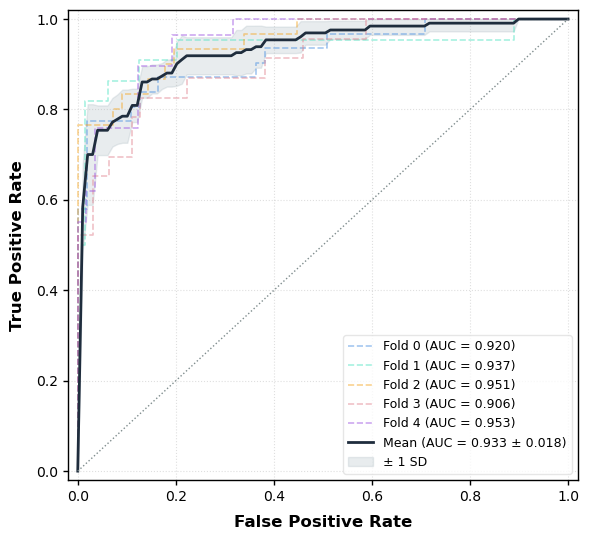

Saved ROC to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/MedCAT/roc_5fold.svg


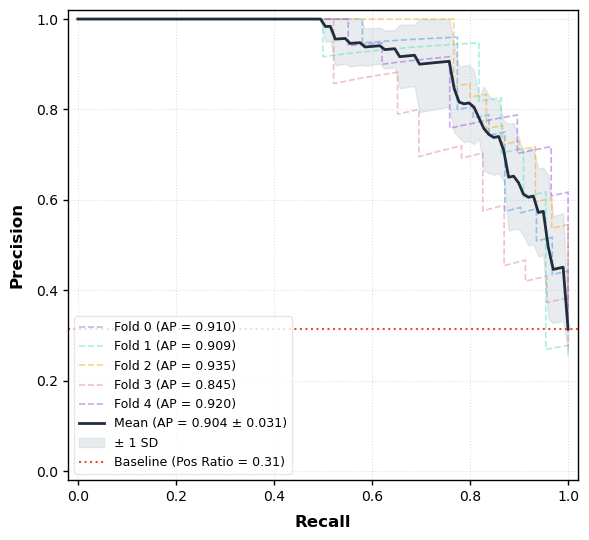

Saved PR to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/MedCAT/pr_5fold.svg


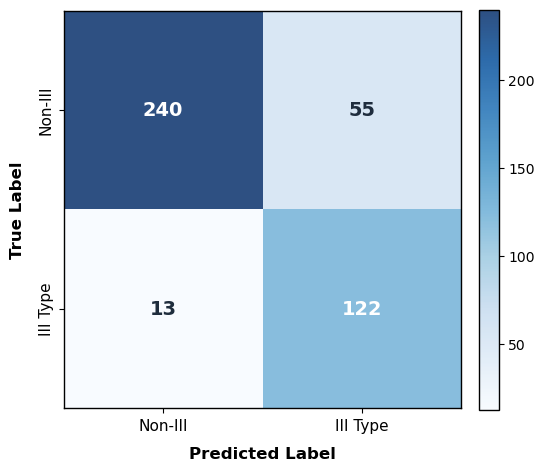

Saved Confusion Matrix to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/MedCAT/cm_total.png

结果已保存到 /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/MedCAT/5fold_results.pkl


In [19]:
#!/usr/bin/env python3
"""
5-Fold MedicalGMU 统一评估脚本
- 固定阈值 0.25（部署阈值）
- 绘制平均 ROC / PR 曲线
- 绘制合并混淆矩阵
"""

import os
import pickle
import warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
	roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
	confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 中文字体（如有需要）
rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False

# # ========== 配置 ==========
# CONFIG = {
# 	'pkl_path': './clinical.pkl',
# 	'image_root': image_root,
# 	'checkpoint_dir': './age/MedCAT_checkpoints03',  # 你的5个pt文件目录
# 	'img_size': 224,
# 	'batch_size': 8,
# 	'threshold': 0.25,          # 统一部署阈值
# 	'num_folds': 5,
# 	'seed': 42,
# 	'device': 'cuda' if torch.cuda.is_available() else 'cpu',
# 	'dropout': 0.4,

# }


# ========== 3. 主流程 ==========

def main_evaluate_5fold():
	print("=" * 60)
	print("5-Fold MedicalCAT 统一评估")
	print(f"统一阈值: {CONFIG['threshold']}")
	print("=" * 60)

	# 获取所有病人ID（与训练时完全一致）
	all_pids = sorted([p.name for p in Path(CONFIG['image_root']).iterdir() if p.is_dir()])
	print(f"总病人: {len(all_pids)}")

	# 重建5折划分（必须与训练时完全一致！）
	# 注意： StratifiedGroupKFold 需要标签，这里用 patient-level 标签
	# 如果你训练时用的是 GroupShuffleSplit(n_splits=5)，需要改成 StratifiedGroupKFold
	# 下面假设你训练时用了 StratifiedGroupKFold，且能重建 patient_labels
	# 如果不能，请从原始Excel重新生成 patient-level 标签
	
	# 读取临床表获取 patient-level 标签（用于 stratify）
	df = pd.read_pickle(CONFIG['pkl_path'])
	df['patient_id'] = df['patient_id'].astype(str).str.strip()
	# 去重取每个病人的标签（假设同病人两关节标签一致；如不一致取max）
	patient_df = df.groupby('patient_id').agg({
		'has_syrinx': 'first', 'scale2_1': 'first',  # 占位
		'syrinx_num': 'first'
	}).reset_index()
	# 注意：这里需要 patient-level 的 III型标签用于 stratify
	# 如果你的 pkl 里没有 label，需要从原始Excel重新生成并合并
	# 简化：假设 patient_df 里有 'label' 列（0/1）
	# 如果没有，需要手动添加：
	# patient_df['label'] = ...  # 从原始数据生成
	
	# 如果无法 stratify，用 GroupKFold 也行
	from sklearn.model_selection import StratifiedGroupKFold
	sgkf = StratifiedGroupKFold(n_splits=CONFIG['num_folds'], shuffle=True, random_state=CONFIG['seed'])
	
	# 注意：y 必须是 patient-level 标签数组，groups=patient_ids
	# 这里需要你确保 patient_df 有正确的 label 列
	# 如果确实没有，可以先用 dummy，但划分必须与训练时一致
	# 最简单的方法：训练时保存 fold_indices.pkl，这里直接加载
	# 下面代码假设你保存了 fold 划分
	
	# ========== 推荐：从训练时保存的 fold_indices.pkl 加载 ==========
	# 如果你训练时没保存，现在需要手动重建（确保 random_state 和顺序一致）
	
	fold_results = {}      # {fold_idx: (labels, probs)}
	all_fold_metrics = []  # 列表存每折指标
	all_labels_total = []
	all_preds_total = []
	kf = KFold(n_splits=5, shuffle=True, random_state=42)
	fold_results = {}
	fold_results2= {}
	all_metrics = []
	all_acc = []
	all_loss = []
	# 3. 按病人 GroupShuffleSplit（8:2）
	# 注意：dummy y 用于 stratify，实际按病人分组
	# 如需 stratify，需先知道每个病人的标签（这里简化，随机分；如需按标签分层，可预计算病人级标签）
	for fold_idx, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
	# for fold_idx in range(1, CONFIG['num_folds'] + 1):
		ckpt_path = os.path.join(CONFIG['checkpoint_dir'], f'{fold_idx+1}_medicalgmu_best.pt')
		print(f"\n--- Fold {fold_idx} ---")
		
		# ckpt = torch.load(ckpt_path, map_location=CONFIG['device'])
		ckpt = torch.load(ckpt_path, map_location=CONFIG['device'], weights_only=False)
		# 加载该折的 scaler 和 patient_ids
		scaler = ckpt['scaler']
		# 如果 ckpt 里保存了 train/val patient_ids，优先用
		# if 'val_patient_ids' in ckpt:
		#     val_pids = ckpt['val_patient_ids']
		# else:
		#     # 否则需要重建，这里简化：假设你保存了
		#     raise KeyError("Checkpoint 里没有 val_patient_ids，请从训练日志恢复或重新划分")
		val_pids = [all_pids[i] for i in val_idx]
		train_pids = [all_pids[i] for i in train_idx]
		train_ds = ChiariXrayDataset(
		CONFIG['pkl_path'], CONFIG['image_root'], train_pids,
		transform=get_transforms('val'), scaler=scaler, fit_scaler=False
		)
		train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)



		# 构建验证集
		val_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], val_pids,
			transform=get_transforms('val'), scaler=scaler, fit_scaler=False
		)
		val_loader = DataLoader(val_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)

		# 加载模型
		model = MedicalConcatNet(num_cont=8, clin_out=16).to(CONFIG['device'])
		model.load_state_dict(ckpt['model_state'])

		# metrics, labels,  preds, probs = evaluate(
		# 	model, val_loader, CONFIG['device'], CONFIG['threshold']
		# )
		metrics, labels,  preds, probs,joint_id = evaluate_joint_level(
			model, val_loader, CONFIG['device'], search_threshold= False,best_t =0.25
		)
		best_thresh = metrics['threshold']
		print(best_thresh)
		
		all_fold_metrics.append(metrics)
		fold_results[fold_idx] = (labels, probs,joint_id)
		fold_results2[fold_idx] = (labels, probs)
		# fold_results.append((labels, probs))
		all_labels_total.extend(labels)
		all_preds_total.extend(preds)

		print(f"  AUC: {metrics['auc']:.3f} | AP: {metrics['ap']:.3f}")
		print(f"  Acc: {metrics['accuracy']:.3f} | Sen: {metrics['sensitivity']:.3f} | "
				f"Spe: {metrics['specificity']:.3f} | Pr:{metrics['precision']:.3f}")
		print(f"  PPV: {metrics['ppv']:.3f} | NPV: {metrics['npv']:.3f} | "
				f"F1: {metrics['f1']:.3f}")
		print(f"  TP={metrics['tp']} FP={metrics['fp']} TN={metrics['tn']} FN={metrics['fn']}")

	# ========== 汇总表格 ==========
	print("\n" + "=" * 60)
	print(f"5-Fold 汇总 (Threshold={CONFIG['threshold']})")
	print("=" * 60)
	
	keys = ['auc', 'ap', 'accuracy', 'sensitivity', 'specificity', 'precision','ppv', 'npv', 'f1']
	print(f"{'Metric':<<15} " + " ".join([f"F{i:<7}" for i in range(1, 6)]) + " Mean±Std")
	for k in keys:
		vals = [m[k] for m in all_fold_metrics]
		mean = np.mean(vals)
		std = np.std(vals)
		print(f"{k:<15} " + " ".join([f"{v:.3f}  " for v in vals]) + f" {mean:.3f}±{std:.3f}")

	# ========== 绘图 ==========
	plot_roc_curves(fold_results2, save_path=CONFIG['checkpoint_dir']/'roc_5fold.svg')
	plot_pr_curves(fold_results2, save_path=CONFIG['checkpoint_dir']/'pr_5fold.svg')
	plot_confusion_matrix_total(np.array(all_labels_total), np.array(all_preds_total),
								save_path=CONFIG['checkpoint_dir']/'cm_total.png')

	# 保存结果
	results = {
		'threshold': CONFIG['threshold'],
		'fold_metrics': all_fold_metrics,
		'fold_results': fold_results,
		'mean': {k: float(np.mean([m[k] for m in all_fold_metrics])) for k in keys},
		'std': {k: float(np.std([m[k] for m in all_fold_metrics])) for k in keys}
	}
	# with open('5fold_results.pkl', 'wb') as f:
	# 	pickle.dump(results, f)
	# print("\n结果已保存到 5fold_results.pkl")
	with open(os.path.join(CONFIG['checkpoint_dir'], '5fold_results.pkl'), 'wb') as f:
		pickle.dump(results, f)
	print(f"\n结果已保存到 {os.path.join(CONFIG['checkpoint_dir'], '5fold_results.pkl')}")

if __name__ == '__main__':
	main_evaluate_5fold()